In [2]:
import pandas as pd
import os
from skimage.transform import resize
from skimage.io import imread
import numpy as np
import matplotlib.pyplot as plt
from skimage import io, transform
from sklearn import preprocessing
import numpy as np
import joblib
import cv2



from sklearn import svm
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB
from sklearn.datasets import load_iris
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,VotingClassifier


In [3]:
path = r"C:\Users\Srinitha\OneDrive\Desktop\mini project\Meat freshness"
model_folder = "model"
categories = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
categories

['FRESH', 'SPOILED']

In [4]:
X_file = os.path.join(model_folder, "X.txt.npy")
Y_file = os.path.join(model_folder, "Y.txt.npy")
if os.path.exists(X_file) and os.path.exists(Y_file):
    X = np.load(X_file)
    Y = np.load(Y_file)
    print("X and Y arrays loaded successfully.")
else:
    X = [] # input array
    Y = [] # output array
    for root, dirs, directory in os.walk(path):
        for j in range(len(directory)):
            name = os.path.basename(root)
            print(f'Loading category: {dirs}')
            print(name+" "+root+"/"+directory[j])
            if 'Thumbs.db' not in directory[j]:
                img_array = cv2.imread(root+"/"+directory[j])
                img_resized = resize(img_array, (64, 64, 3))
                # Append the input image array to X
                X.append(img_resized.flatten())
                # Append the index of the category in categories list to Y
                Y.append(categories.index(name))
    X = np.array(X)
    Y = np.array(Y)

    np.save(X_file, X)
    np.save(Y_file, Y)

X and Y arrays loaded successfully.


In [5]:
# Splitting the data into training and testing sets
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.20,random_state=77)

In [6]:
accuracy=[]
precision = []
recall = []
fscore = []
# Overall metrics table
overall_results = []

# Class-wise metrics table
classwise_results = []


In [7]:
def calculateMetrics(algorithm, predict, testY, labels):

    # Overall metrics
    a = accuracy_score(testY, predict) * 100
    p = precision_score(testY, predict, average='macro') * 100
    r = recall_score(testY, predict, average='macro') * 100
    f = f1_score(testY, predict, average='macro') * 100

    # Save overall metrics
    overall_results.append({
        "Algorithm": algorithm,
        "Accuracy (%)": a,
        "Precision (%)": p,
        "Recall (%)": r,
        "F1 Score (%)": f
    })

    print(f"{algorithm} Accuracy: {a:.2f}")
    print(f"{algorithm} Precision: {p:.2f}")
    print(f"{algorithm} Recall: {r:.2f}")
    print(f"{algorithm} F1 Score: {f:.2f}\n")

    # Classification report & confusion matrix
    report = classification_report(testY, predict, target_names=labels, output_dict=True)
    conf_matrix = confusion_matrix(testY, predict)

    # Class-wise accuracy
    class_accuracy = conf_matrix.diagonal() / conf_matrix.sum(axis=1)

    print(f"{algorithm} Class-wise Metrics:")
    print(f"{'Class':<12}{'Accuracy':<12}{'Precision':<12}{'Recall':<12}{'F1 Score':<12}")

    for i, class_name in enumerate(labels):
        acc = class_accuracy[i] * 100
        prec = report[class_name]['precision'] * 100
        rec = report[class_name]['recall'] * 100
        f1 = report[class_name]['f1-score'] * 100

        print(f"{class_name:<12}{acc:<12.2f}{prec:<12.2f}{rec:<12.2f}{f1:<12.2f}")

        # Save class-wise metrics
        classwise_results.append({
            "Algorithm": algorithm,
            "Class": class_name,
            "Accuracy (%)": acc,
            "Precision (%)": prec,
            "Recall (%)": rec,
            "F1 Score (%)": f1
        })

    # Confusion matrix plot
    plt.figure(figsize=(5, 5))
    sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.title(f"{algorithm} Confusion Matrix")
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.show()


Multinomial NBC Accuracy: 76.84
Multinomial NBC Precision: 77.23
Multinomial NBC Recall: 76.45
Multinomial NBC F1 Score: 76.53

Multinomial NBC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       83.92       75.00       83.92       79.21       
SPOILED     68.99       79.46       68.99       73.86       


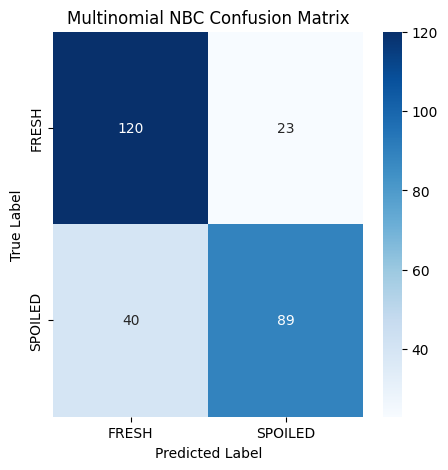

In [8]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "Multi_NBC_Model.pkl")
if os.path.exists(Model_file):
    # Load the model from the pkl file
    nb_classifier = joblib.load(Model_file)
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Multinomial NBC", y_pred, y_test, categories)
else:
    # Create a Gaussian Naive Bayes classifier
    nb_classifier = MultinomialNB()
    # Train the classifier on the training data
    nb_classifier.fit(x_train, y_train)
    # Save the model weights to a pkl file
    joblib.dump(nb_classifier, Model_file)  
    y_pred = nb_classifier.predict(x_test)
    calculateMetrics("Multinomial NBC", y_pred, y_test, categories)

DTC Accuracy: 84.93
DTC Precision: 84.97
DTC Recall: 85.06
DTC F1 Score: 84.92

DTC Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       82.52       88.06       82.52       85.20       
SPOILED     87.60       81.88       87.60       84.64       


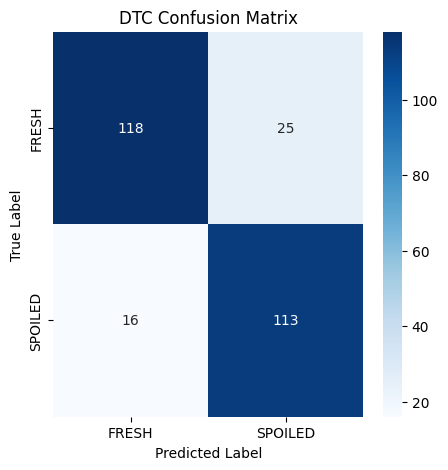

In [9]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "DTC_Model.pkl")
if os.path.exists(Model_file):
    dt_classifier = joblib.load(Model_file)
    y_pred = dt_classifier.predict(x_test)
    calculateMetrics("DTC", y_pred, y_test, categories)
else:
    dt_classifier = DecisionTreeClassifier()
    dt_classifier.fit(x_train, y_train)
    joblib.dump(dt_classifier, Model_file)  
    y_pred = dt_classifier.predict(x_test)
    calculateMetrics("DTC", y_pred, y_test, categories)

In [12]:
# Check if the pkl file exists
    Model_file = os.path.join(model_folder, "VT_Model.pkl")
    if os.path.exists(Model_file):
        vt_classifier = joblib.load(Model_file)
        y_pred = vt_classifier.predict(x_test)
        calculateMetrics("VT", y_pred, y_test, categories)
    else:
        lr = LogisticRegression(max_iter=1000)
        dt = DecisionTreeClassifier(random_state=42)
        et = ExtraTreesClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    
        vt_classifier = VotingClassifier(
            estimators=[
                ('lr', lr),
                ('dt', dt),
                ('et', et)
            ],
            voting='soft'   # soft voting = better performance
        )
        vt_classifier.fit(x_train, y_train)
        joblib.dump(vt_classifier, Model_file)  
        y_pred = vt_classifier.predict(x_test)
        calculateMetrics("Voting", y_pred, y_test, categories)

IndentationError: unexpected indent (1323941934.py, line 2)

Extra Trees Accuracy: 94.49
Extra Trees Precision: 94.80
Extra Trees Recall: 94.30
Extra Trees F1 Score: 94.45

Extra Trees Class-wise Metrics:
Class       Accuracy    Precision   Recall      F1 Score    
FRESH       97.90       92.11       97.90       94.92       
SPOILED     90.70       97.50       90.70       93.98       


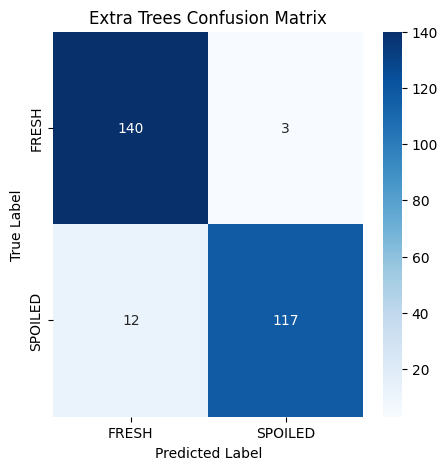

In [11]:
# Check if the pkl file exists
Model_file = os.path.join(model_folder, "EX_Model.pkl")
if os.path.exists(Model_file):
    ex_classifier = joblib.load(Model_file)
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)
else:
    ex_classifier = ExtraTreesClassifier()
    ex_classifier.fit(x_train, y_train)
    joblib.dump(ex_classifier, Model_file)  
    y_pred = ex_classifier.predict(x_test)
    calculateMetrics("Extra Trees", y_pred, y_test, categories)

In [11]:
overall_df = pd.DataFrame(overall_results)
overall_df


,Algorithm,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Multinomial NBC,76.838235,77.232143,76.454166,76.533421
1,DTC,84.926471,84.971880,85.057191,84.921375
2,Extra Trees,94.485294,94.802632,94.299886,94.445579


In [12]:
classwise_df = pd.DataFrame(classwise_results)
classwise_df


,Algorithm,Class,Accuracy (%),Precision (%),Recall (%),F1 Score (%)
0,Multinomial NBC,FRESH,83.916084,75.000000,83.916084,79.207921
1,Multinomial NBC,SPOILED,68.992248,79.464286,68.992248,73.858921
2,DTC,FRESH,82.517483,88.059701,82.517483,85.198556
3,DTC,SPOILED,87.596899,81.884058,87.596899,84.644195
4,Extra Trees,FRESH,97.902098,92.105263,97.902098,94.915254
5,Extra Trees,SPOILED,90.697674,97.500000,90.697674,93.975904


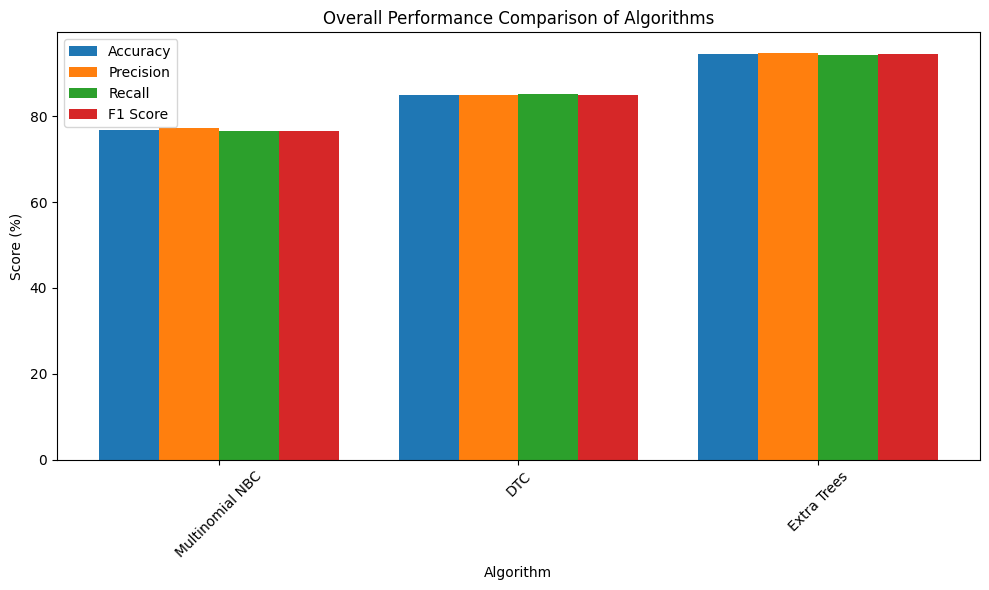

In [13]:
import numpy as np

# X locations
x = np.arange(len(overall_df['Algorithm']))
width = 0.2

plt.figure(figsize=(10,6))

plt.bar(x - 1.5*width, overall_df['Accuracy (%)'], width, label='Accuracy')
plt.bar(x - 0.5*width, overall_df['Precision (%)'], width, label='Precision')
plt.bar(x + 0.5*width, overall_df['Recall (%)'], width, label='Recall')
plt.bar(x + 1.5*width, overall_df['F1 Score (%)'], width, label='F1 Score')

plt.xticks(x, overall_df['Algorithm'], rotation=45)
plt.xlabel("Algorithm")
plt.ylabel("Score (%)")
plt.title("Overall Performance Comparison of Algorithms")
plt.legend()
plt.tight_layout()
plt.show()


In [1]:
plt.figure(figsize=(10,6))
sns.barplot(
    data=classwise_df,
    x="Algorithm",
    y="F1 Score (%)",
    hue="Class"
)
plt.title("Class-Wise F1 Score Comparison")
plt.xlabel("Algorithm")
plt.ylabel("F1 Score (%)")
plt.xticks(rotation=45)
plt.legend(title="Class")
plt.show()


NameError: name 'plt' is not defined

In [1]:
path=r"C:\Users\anjus\OneDrive\Apps\Desktop\project\casting product\casting\def_front\cast_def_0_0.jpeg"
img=imread(path)
img_resize=resize(img,(64,64,3))
img_preprocessed=[img_resize.flatten()]
output_number=ex_classifier.predict(img_preprocessed)[0]
output_name=categories[output_number]

plt.imshow(img)
plt.text(10, 10, f'Predicted Output: {output_name}', color='white', fontsize=12, weight='bold', backgroundcolor='black')
plt.axis('off')
plt.show()

NameError: name 'imread' is not defined

In [2]:
path=r"C:\Users\anjus\OneDrive\Apps\Desktop\project\casting product\casting\def_front\cast_def_0_0.jpeg"
img=imread(path)
img_resize=resize(img,(64,64,3))
img_preprocessed=[img_resize.flatten()]
output_number=ex_classifier.predict(img_preprocessed)[0]
output_name=categories[output_number]

plt.imshow(img)
plt.text(10, 10, f'Predicted Output: {output_name}', color='white', fontsize=12, weight='bold', backgroundcolor='black')
plt.axis('off')
plt.show()

NameError: name 'imread' is not defined